# Diagnostic: what kinds of bad reasoning steps can the PMI metric actually detect?

**Run the baseline notebook first.** This one loads `baseline_results.json`, which that notebook
produces.

### The idea

The metric gives every reasoning step a score. The claim is that a low score means a bad step.
To test that, we need steps we *know* are bad. Real model mistakes are not labelled, so instead
we take reasoning that is already correct and **break it on purpose**, in four different ways.
Since we broke it ourselves, we know exactly which step is the bad one.

Then we ask: does the broken step get the lowest score?

| tag | what we break | question it answers |
|---|---|---|
| `arith` | change one digit of a computed result (`24` → `27`) | can it see a **wrong number**? |
| `ungrounded` | paste in a step from a *different* problem | can it see a step **that doesn't belong**? |
| `filler` | insert an empty phrase ("Let me think carefully about this") | can it see **padding**? |
| `restate` | insert a correct but pointless restatement of a given number | **control**: padding that is not an error |

The last one matters. If `filler` and `restate` both score badly, the metric is detecting
*pointlessness*, not *wrongness* — and those are very different claims.

### Why this connects to the baseline notebook

The baseline notebook produced a pie chart of what the model actually gets wrong. If `arith`
was the biggest slice there, and the metric turns out to be blind to `arith` here, then the
conclusion writes itself: **this metric cannot catch the dominant failure mode on GSM8K.**
That is a real finding, not a failed experiment. The last section comes back to this.

### Write down your prediction before running

Seriously — write it in your notes now. Mine is `filler` > `ungrounded` > `arith`, with `arith`
near chance. Being wrong about it is fine and interesting; deciding what you expected *after*
seeing the numbers is not.

## 1. Setup

In [1]:
!pip install -q transformers datasets accelerate scikit-learn matplotlib pandas

In [2]:
import re
import json
import random

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm.auto import tqdm

SEED = 0
rng = random.Random(SEED)
np.random.seed(SEED)

MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="auto")
model.eval()
DEVICE = model.device

gsm8k = load_dataset("openai/gsm8k", "main")
print("Model on:", DEVICE)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Model on: cuda:0


### The prompt must be identical to the baseline notebook

This string is copied from the baseline notebook character for character. **If you change it in
one notebook, change it in the other too.** The whole point of the metric is to measure how much
the prompt constrains a step, so a different prompt is literally a different experiment, and the
two chapters would no longer be talking about the same thing.

In [3]:
# ---- must match the baseline notebook exactly ----
SYSTEM_PROMPT = (
    "You are a precise mathematical assistant. "
    "Solve the following word problem step-by-step. "
    "Provide clear reasoning, and end your response by stating the final answer "
    "in the format: The final answer is #### [number]."
)

def build_prompt(question):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    return tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True)

def encode(text):
    """Text -> token id tensor. No extra special tokens (the template has them already)."""
    return tokenizer(text, return_tensors="pt",
                     add_special_tokens=False)["input_ids"][0]

## 2. Where the clean reasoning comes from

Two options:

- `"model"` (default) — the traces the model wrote itself in the baseline notebook, keeping only
  the ones it got **right**. These are correct reasoning in the model's own style.
- `"gold"` — the human-written reference solutions from GSM8K.

Default is `"model"`, and that is a deliberate choice. The gold solutions are written in a terse
style that is quite different from how this model writes, and the model may find that style
unusually easy or unusually hard to predict. Using its own correct output keeps the comparison
fair and keeps this notebook connected to the baseline one.

Try `"gold"` afterwards as a robustness check. If the numbers move a lot, that is worth a
paragraph in the thesis.

In [4]:
TRACE_SOURCE = "model"     # "model" or "gold"

CALC_ANNOTATION = re.compile(r"<<[^>]*>>")

def split_into_steps(text):
    """Split a reasoning trace into steps, one per line. Drops the final-answer line."""
    steps = []
    for line in text.strip().split("\n"):
        line = CALC_ANNOTATION.sub("", line).strip()
        if not line:
            continue
        if "####" in line or "final answer" in line.lower():
            continue          # the answer itself is not a reasoning step
        steps.append(line)
    return steps


def load_clean_traces(source):
    """Return a list of {question, steps} where the reasoning is known to be correct."""
    items = []

    if source == "model":
        try:
            with open("baseline_results.json") as f:
                baseline = json.load(f)
        except FileNotFoundError:
            raise FileNotFoundError(
                "baseline_results.json not found. Run the baseline notebook first.")
        for r in baseline:
            if r.get("status") != "correct":
                continue                      # only keep traces that were right
            steps = split_into_steps(r["trace"])
            if len(steps) >= 2:
                items.append({"question": r["question"], "steps": steps})

    elif source == "gold":
        for q, a in zip(gsm8k["test"]["question"], gsm8k["test"]["answer"]):
            steps = split_into_steps(a.split("####")[0])
            if len(steps) >= 2:
                items.append({"question": q, "steps": steps})

    else:
        raise ValueError("TRACE_SOURCE must be 'model' or 'gold'")

    return items


clean_items = load_clean_traces(TRACE_SOURCE)
rng.shuffle(clean_items)

print(f"source = {TRACE_SOURCE}")
print(f"usable clean traces: {len(clean_items)}")
print(f"average steps per trace: {np.mean([len(x['steps']) for x in clean_items]):.1f}")
print()
print("=== example ===")
for s in clean_items[0]["steps"]:
    print(" *", s)

source = model
usable clean traces: 161
average steps per trace: 9.0

=== example ===
 * Let's break down the problem step-by-step:
 * 1. Dylan bought 38 chicken sausages.
 * 2. He bought 6 more fish sausages than chicken sausages, so the number of fish sausages is 38 + 6 = 44.
 * 3. To find the total number of sausages, we add the number of chicken sausages and fish sausages: 38 (chicken) + 44 (fish) = 82.


**If you get very few traces here**, the baseline notebook probably ran on too few problems,
or the model got most of them wrong. Raise `N_SAMPLES` there and re-run it. You want at least
100 clean traces for the numbers below to mean anything.

## 3. Scoring a step

For one step $S$ we compute two numbers:

- $\ell_c = \log P(S \mid \text{question} + \text{earlier steps})$ — how likely the step is
  when the model can see the problem.
- $\ell_0 = \log P(S \mid \text{some other problem} + \text{earlier steps})$ — how likely the
  same words are when the model is looking at a *different* problem.

The difference $\ell_c - \ell_0$ is how much this particular problem made the step likely. We
divide by the number of tokens so that long steps don't automatically get bigger numbers:

$$\text{pmi\_per\_token} = \frac{\ell_c - \ell_0}{\text{number of tokens in } S}$$

Two extra columns are computed as **baselines to compare against**, not as results:

- `mean_lp_cond` = $\ell_c$ per token. Just the model's confidence, with no comparison at all.
  If this does as well as the PMI columns, the comparison step is not buying anything and you
  should say so.
- `n_tokens` = step length. If *this* predicts the corrupted step well, the metric may just be
  detecting "this step is short" or "this step is long".

Including baselines you might lose to is the point. A number is only meaningful next to
something else.

In [5]:
K_OTHER = 3           # how many "other problems" to average over
QUESTION_POOL = list(gsm8k["train"]["question"][:400])

def other_problem_prompts(this_question):
    """Token ids for K_OTHER prompts built from unrelated problems."""
    picks = [q for q in rng.sample(QUESTION_POOL, K_OTHER + 2) if q != this_question]
    return [encode(build_prompt(q)) for q in picks[:K_OTHER]]


@torch.no_grad()
def token_logprobs(prefix_ids, cont_ids):
    """log P(token) for each token of cont_ids, given prefix_ids before it."""
    ids = torch.cat([prefix_ids, cont_ids]).unsqueeze(0).to(DEVICE)
    logits = model(ids).logits[0].float()      # cast to float32 before log_softmax
    n_prefix = prefix_ids.shape[0]
    # position i predicts token i+1, so shift by one
    lp = torch.log_softmax(logits[n_prefix - 1 : -1, :], dim=-1)
    return lp[torch.arange(cont_ids.shape[0], device=DEVICE), cont_ids.to(DEVICE)].cpu()


def build_trace_ids(steps):
    """Encode each step separately and concatenate, so we know exactly where each step is."""
    chunks, spans, pos = [], [], 0
    for s in steps:
        ids = encode(s.rstrip() + "\n")
        chunks.append(ids)
        spans.append((pos, pos + ids.shape[0]))
        pos += ids.shape[0]
    return torch.cat(chunks), spans


@torch.no_grad()
def score_steps(question, steps):
    """Score every step of one trace. Returns a list of dicts."""
    prompt_ids = encode(build_prompt(question))
    trace_ids, spans = build_trace_ids(steps)

    # with the real question
    lp_cond = token_logprobs(prompt_ids, trace_ids)

    # with unrelated questions, averaged
    others = [token_logprobs(p, trace_ids) for p in other_problem_prompts(question)]
    lp_other = torch.stack(others).mean(0)

    scored = []
    for i, (start, end) in enumerate(spans):
        n = end - start
        lc = float(lp_cond[start:end].sum())
        l0 = float(lp_other[start:end].sum())
        scored.append({
            "step_idx": i,
            "text": steps[i],
            "n_tokens": n,
            "pmi_per_token": (lc - l0) / max(n, 1),
            "mean_lp_cond": lc / max(n, 1),      # baseline
        })
    return scored

## 4. The four ways of breaking a trace

One detail that matters: **all four corruptions happen at step 1 or later, never at step 0.**
The first step of a trace behaves differently from the rest (it has no previous steps to build
on), so if one corruption type could land there and another couldn't, part of any difference
between them would just be position rather than the corruption itself.

`arith` also keeps the token count identical — it changes a digit, not the size of the number.
That is on purpose: it stops the detector from succeeding just because the step got longer or
shorter. It makes `arith` the hardest case, which is exactly what we want to test.

In [6]:
FILLERS = [
    "Let me think carefully about this problem.",
    "This is an important thing to consider here.",
    "Now we need to be careful with the next part.",
    "Let us go through this step by step.",
    "It is worth pausing to check our reasoning.",
]

RESULT_PATTERN = re.compile(r"=\s*(\d+)")


def corrupt_arith(steps):
    """Change the last digit of a computed result. Same length, same position."""
    candidates = [i for i in range(1, len(steps)) if RESULT_PATTERN.search(steps[i])]
    if not candidates:
        return None
    i = rng.choice(candidates)
    matches = list(RESULT_PATTERN.finditer(steps[i]))
    m = matches[-1]                       # the last "= number" in the step
    number = m.group(1)
    old_digit = int(number[-1])
    new_digit = rng.choice([d for d in range(10) if d != old_digit])
    new_number = number[:-1] + str(new_digit)

    start, end = m.span(1)
    new_steps = list(steps)
    new_steps[i] = steps[i][:start] + new_number + steps[i][end:]
    return new_steps, i


def corrupt_ungrounded(steps, donor_steps):
    """Insert a step taken from a different problem's reasoning."""
    i = rng.randrange(1, len(steps) + 1)
    new_steps = list(steps)
    new_steps.insert(i, rng.choice(donor_steps))
    return new_steps, i


def corrupt_filler(steps):
    """Insert an empty phrase."""
    i = rng.randrange(1, len(steps) + 1)
    new_steps = list(steps)
    new_steps.insert(i, rng.choice(FILLERS))
    return new_steps, i


def corrupt_restate(steps, question):
    """Insert a true but useless restatement of a number from the question."""
    numbers = re.findall(r"\d[\d,]*", question)
    if not numbers:
        return None
    n = rng.choice(numbers)
    i = rng.randrange(1, len(steps) + 1)
    new_steps = list(steps)
    new_steps.insert(i, f"The problem tells us that this value is {n}.")
    return new_steps, i


# --- quick check that they do what they say ---
demo = clean_items[0]["steps"]
print("ORIGINAL:")
for s in demo:
    print("  ", s)
for name, fn in [("arith", lambda: corrupt_arith(demo)),
                 ("filler", lambda: corrupt_filler(demo)),
                 ("restate", lambda: corrupt_restate(demo, clean_items[0]["question"]))]:
    out = fn()
    if out is None:
        print(f"\n{name}: not applicable to this trace")
        continue
    new_steps, idx = out
    print(f"\n{name}: broken step is index {idx} ->", new_steps[idx])

ORIGINAL:
   Let's break down the problem step-by-step:
   1. Dylan bought 38 chicken sausages.
   2. He bought 6 more fish sausages than chicken sausages, so the number of fish sausages is 38 + 6 = 44.
   3. To find the total number of sausages, we add the number of chicken sausages and fish sausages: 38 (chicken) + 44 (fish) = 82.

arith: broken step is index 3 -> 3. To find the total number of sausages, we add the number of chicken sausages and fish sausages: 38 (chicken) + 44 (fish) = 81.

filler: broken step is index 1 -> It is worth pausing to check our reasoning.

restate: broken step is index 2 -> The problem tells us that this value is 38.


## 5. Run it

Start with `N_ITEMS = 20` to check it runs, then raise it. Each trace needs
`1 + K_OTHER = 4` forward passes and there is no text generation, so this is much faster than
the baseline notebook.

In [7]:
N_ITEMS = 200

items = clean_items[:N_ITEMS]

# Steps borrowed from *other* problems, for the `ungrounded` corruption.
# Taken from traces we are NOT using, so nothing is reused.
donor_bank = []
for item in clean_items[N_ITEMS:N_ITEMS + 200]:
    donor_bank.extend(item["steps"])
print("donor steps available:", len(donor_bank))

rows = []
trace_id = 0

for item in tqdm(items):
    question, steps = item["question"], item["steps"]

    variants = {}
    r = corrupt_arith(steps)
    if r is not None:
        variants["arith"] = r
    if donor_bank:
        variants["ungrounded"] = corrupt_ungrounded(steps, donor_bank)
    variants["filler"] = corrupt_filler(steps)
    r = corrupt_restate(steps, question)
    if r is not None:
        variants["restate"] = r

    for tag, (broken_steps, broken_idx) in variants.items():
        scored = score_steps(question, broken_steps)
        for s in scored:
            rows.append({
                **s,
                "tag": tag,
                "trace_id": trace_id,
                "is_corrupt": int(s["step_idx"] == broken_idx),
                "n_steps": len(broken_steps),
            })
        trace_id += 1

df = pd.DataFrame(rows)
df.to_csv("perturbation_scores.csv", index=False)
print(f"\nscored {len(df)} steps across {trace_id} broken traces")
print(df.groupby("tag")["trace_id"].nunique())

donor steps available: 0


  0%|          | 0/161 [00:00<?, ?it/s]


scored 4463 steps across 458 broken traces
tag
arith      138
filler     161
restate    159
Name: trace_id, dtype: int64


## 6. Results

Two numbers per corruption type and per metric:

**AUC** — take all the steps, use the score to rank them, and ask how often the broken step ranks
as more suspicious than a clean one. 0.5 means the metric is useless (same as guessing). 1.0
means perfect. Scores are negated first, because *low* score is supposed to mean *suspicious*.

**detect@1** — in each broken trace, look at the single worst-scoring step. How often is it the
one we actually broke? This is what matters if you ever want to *point at* the faulty step. The
`chance` column shows what you'd get by picking at random, which is roughly 1 / (number of steps).

The confidence interval comes from bootstrapping: resample the data 1000 times and see how much
the AUC moves. If the interval includes 0.5, you cannot claim the metric works, no matter what
the point estimate looks like.

In [8]:
from sklearn.metrics import roc_auc_score

METRICS = ["pmi_per_token", "mean_lp_cond", "n_tokens"]
BASELINE_METRICS = {"mean_lp_cond", "n_tokens"}

def bootstrap_auc(labels, scores, n_rounds=1000):
    gen = np.random.default_rng(0)
    values = []
    for _ in range(n_rounds):
        idx = gen.integers(0, len(labels), len(labels))
        if labels[idx].min() == labels[idx].max():
            continue
        values.append(roc_auc_score(labels[idx], scores[idx]))
    if not values:
        return np.nan, np.nan
    return np.percentile(values, 2.5), np.percentile(values, 97.5)


table = []
for tag, group in df.groupby("tag"):
    labels = group["is_corrupt"].values
    chance = float((1.0 / group["n_steps"]).mean())

    for metric in METRICS:
        scores = -group[metric].values          # low value = suspicious

        auc = roc_auc_score(labels, scores)
        lo, hi = bootstrap_auc(labels, scores)

        # detect@1: the worst-scoring step in each trace
        tmp = group.copy()
        tmp["_score"] = scores
        worst = tmp.loc[tmp.groupby("trace_id")["_score"].idxmax()]
        detect1 = worst["is_corrupt"].mean()

        table.append({
            "corruption": tag,
            "metric": metric + ("  (baseline)" if metric in BASELINE_METRICS else ""),
            "AUC": round(auc, 3),
            "95% CI": f"[{lo:.2f}, {hi:.2f}]",
            "detect@1": round(detect1, 3),
            "chance": round(chance, 3),
        })

table = pd.DataFrame(table)
print(table.to_string(index=False))
print()
print("=== AUC summary ===")
print(table.pivot_table(index="corruption", columns="metric", values="AUC").to_string())

corruption                   metric   AUC       95% CI  detect@1  chance
     arith            pmi_per_token 0.773 [0.73, 0.82]     0.420   0.110
     arith mean_lp_cond  (baseline) 0.843 [0.82, 0.87]     0.159   0.110
     arith     n_tokens  (baseline) 0.469 [0.42, 0.52]     0.065   0.110
    filler            pmi_per_token 0.953 [0.93, 0.97]     0.839   0.100
    filler mean_lp_cond  (baseline) 1.000 [1.00, 1.00]     1.000   0.100
    filler     n_tokens  (baseline) 0.808 [0.79, 0.83]     0.348   0.100
   restate            pmi_per_token 0.918 [0.88, 0.95]     0.862   0.099
   restate mean_lp_cond  (baseline) 1.000 [1.00, 1.00]     1.000   0.099
   restate     n_tokens  (baseline) 0.666 [0.64, 0.69]     0.000   0.099

=== AUC summary ===
metric      mean_lp_cond  (baseline)  n_tokens  (baseline)  pmi_per_token
corruption                                                               
arith                          0.843                 0.469          0.773
filler                     

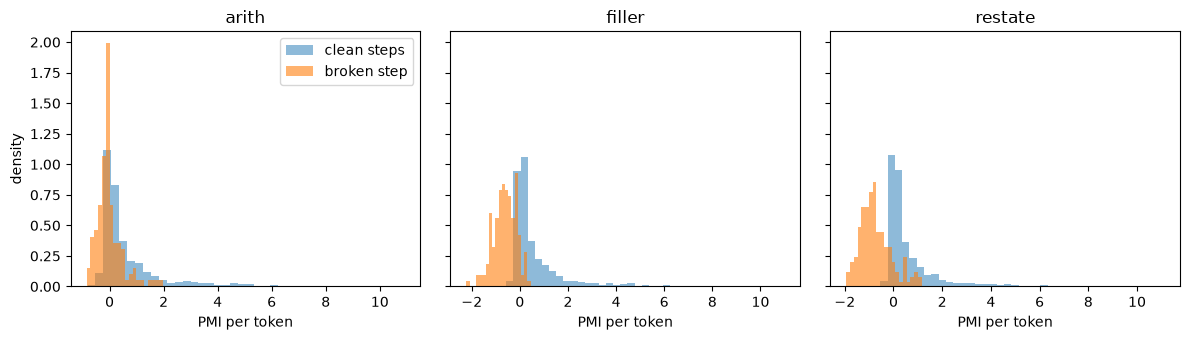

The more the two histograms overlap, the less the metric can tell them apart.


In [9]:
# Distribution of scores: broken steps vs clean steps
tags = sorted(df["tag"].unique())
fig, axes = plt.subplots(1, len(tags), figsize=(4 * len(tags), 3.5), sharey=True)
axes = np.atleast_1d(axes)

for ax, tag in zip(axes, tags):
    g = df[df["tag"] == tag]
    ax.hist(g[g["is_corrupt"] == 0]["pmi_per_token"], bins=40,
            density=True, alpha=0.5, label="clean steps")
    ax.hist(g[g["is_corrupt"] == 1]["pmi_per_token"], bins=20,
            density=True, alpha=0.6, label="broken step")
    ax.set_title(tag)
    ax.set_xlabel("PMI per token")

axes[0].set_ylabel("density")
axes[0].legend()
plt.tight_layout()
plt.savefig("perturbation_distributions.png", dpi=150)
plt.show()

print("The more the two histograms overlap, the less the metric can tell them apart.")

## 7. Tying this back to the baseline notebook

This cell puts the two chapters side by side. It reads the error labels you filled in there and
prints them next to the AUC results here.

In [10]:
try:
    labels_df = pd.read_csv("errors_to_label.csv")
    labels_df = labels_df[labels_df["error_type"].notna()]
    labels_df["error_type"] = labels_df["error_type"].astype(str).str.strip()
    labels_df = labels_df[labels_df["error_type"] != ""]

    print("What the model actually gets wrong (from the baseline notebook):")
    share = labels_df["error_type"].value_counts(normalize=True) * 100
    for name, pct in share.items():
        print(f"   {name:<15} {pct:5.1f}%")
    print()
except FileNotFoundError:
    print("errors_to_label.csv not found - run the baseline notebook's labelling step.\n")

print("What this metric can detect (AUC, pmi_per_token):")
detect = table[table["metric"] == "pmi_per_token"].set_index("corruption")
for tag in detect.index:
    print(f"   {tag:<15} {detect.loc[tag, 'AUC']:.3f}   {detect.loc[tag, '95% CI']}")

print()
print("Compare the two lists. The question for the discussion chapter is whether the")
print("failure types that actually happen are the ones this metric can see.")

What the model actually gets wrong (from the baseline notebook):

What this metric can detect (AUC, pmi_per_token):
   arith           0.773   [0.73, 0.82]
   filler          0.953   [0.93, 0.97]
   restate         0.918   [0.88, 0.95]

Compare the two lists. The question for the discussion chapter is whether the
failure types that actually happen are the ones this metric can see.


## 8. How to read your results

Work through these in order. Each one is a sentence you can put in the thesis.

**Look at `arith` first.** If its AUC is around 0.5 and the confidence interval contains 0.5,
the metric cannot detect wrong arithmetic. Combined with the error distribution above, that is
the main result of the whole project, and it should be stated plainly rather than buried. The
reason is worth explaining: `6 × 7 = 41` and `6 × 7 = 42` are equally ordinary-looking pieces of
English, so a method based on how *expected* the words are has nothing to work with.

**Then check the baseline columns.** If `mean_lp_cond` matches or beats `pmi_per_token`
everywhere, the whole comparison-against-another-problem machinery is not earning its place, and
plain model confidence would do the same job. Report that. If `n_tokens` alone gets a high AUC
on `ungrounded` or `filler`, those results are partly about step length, not step quality.

**Then compare `filler` and `restate`.** Both are pointless steps; only `filler` is content-free.
If both score badly, the metric detects *pointless*, not *wrong*. That is still a useful thing to
detect — you could use it to cut unnecessary steps and save computation — but it is a different
claim, and the thesis should make the smaller, true claim rather than the bigger, unsupported one.

**Finally, sample size.** Look at how wide the confidence intervals are. If two AUCs differ by
0.05 and their intervals overlap heavily, you cannot say one is higher. Either raise `N_ITEMS`
or describe the difference as inconclusive.

## 9. Optional extras, if there is time

1. Set `TRACE_SOURCE = "gold"` and re-run. Does anything change? If yes, the metric is partly
   measuring writing style rather than reasoning.
2. Make the `ungrounded` donor steps roughly the same length as the step they sit next to, then
   re-run. If the AUC drops, length was doing the work.
3. Change `K_OTHER` to 1 and to 5. If the results move a lot, the choice of comparison problems
   matters and needs its own paragraph.
4. Corrupt two steps instead of one and see whether the metric finds both.